# Lab 17: Choosing and Testing Priors

This lab checks what a Bayesian MMM implies about revenue before it has seen any data, using prior predictive sampling.
It starts from a first draft with generic priors, finds the priors that produce implausible businesses, tightens them one group at a time, and arrives at the priors the reference model of the later labs uses.
It accompanies Chapter 17 of the book Marketing Mix Modelling.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import (
    BETA_PRIOR_SHARE,
    REVENUE_SCALE,
    build_controls,
    build_events,
    build_features,
    build_seasonality,
    build_treatments,
    national_aggregate,
    reference_model,
)
from mmm_book.sedge import CHANNELS, generate_sedge

mmm_style()

## The model structure

The structure is the one Lab 15 builds: a baseline (intercept, trend, annual seasonality and the launch event), the promotion treatment, six controls and one non-negative beta per channel, on a national weekly aggregate in millions of pounds.
`draft_model` builds that structure with the prior scales as arguments, so the same model can be tried with different priors.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
feat = build_features(nat)
season = build_seasonality(nat)
events = build_events(nat)
treatments = build_treatments(nat)
controls = build_controls(nat)

y = nat["revenue"].to_numpy(dtype=float) / REVENUE_SCALE
week = nat["week"].to_numpy(dtype=float)
week_c = (week - week.mean()) / week.std()


def draft_model(beta_sigma, coef_sigma, noise_sigma):
    """The Lab 15 structure with the given prior scales (all in GBP millions)."""
    with pm.Model() as model:
        intercept = pm.Normal("intercept", mu=y.mean(), sigma=y.std())
        trend = pm.Normal("trend", 0, coef_sigma)
        season_a = pm.Normal("season_a", 0, coef_sigma)
        season_b = pm.Normal("season_b", 0, coef_sigma)
        omega = {name: pm.Normal(f"omega_{name}", 0, coef_sigma) for name in events}
        delta = {name: pm.Normal(f"delta_{name}", 0, coef_sigma) for name in treatments}
        gamma = {name: pm.Normal(f"gamma_{name}", 0, coef_sigma) for name in controls}
        betas = {ch: pm.HalfNormal(f"beta_{ch}", sigma=beta_sigma) for ch in CHANNELS}
        mu = (
            intercept
            + trend * week_c
            + season_a * season["sin"]
            + season_b * season["cos"]
            + sum(omega[name] * events[name] for name in events)
            + sum(delta[name] * treatments[name] for name in treatments)
            + sum(gamma[name] * controls[name] for name in controls)
            + sum(betas[ch] * feat[ch] for ch in CHANNELS)
        )
        sigma = pm.HalfNormal("sigma", sigma=noise_sigma)
        pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    return model


print(f"observed weekly revenue (GBPm): min={y.min():.2f}, max={y.max():.2f}, mean={y.mean():.2f}")

observed weekly revenue (GBPm): min=0.61, max=1.34, mean=0.92


## What to look at

A prior predictive check draws parameters from the priors alone, before conditioning on any observed data, and pushes them through the model to see what businesses the priors imply.
Chapter 17 asks for the check on the business scale, so `describe` reports two kinds of quantity.
The first is weekly revenue: its 5th and 95th percentiles across all draws and weeks, the share of simulated weeks with negative revenue, and the share above twice the highest week Sedge has seen.
The second is the ROAS each prior implies for OOH, the channel in the book's opening example: a beta is OOH's average weekly contribution, so `beta_ooh * sum(feature) * REVENUE_SCALE / spend` turns it into a ROAS.

In [3]:
ooh_spend = float(nat["ooh_spend"].sum())
ooh_roas_per_beta = float(feat["ooh"].sum()) * REVENUE_SCALE / ooh_spend
summaries = {}


def describe(label, model):
    with model:
        prior = pm.sample_prior_predictive(draws=500, random_seed=RANDOM_SEED)
    pp = prior.prior_predictive["y"].to_numpy().reshape(-1)
    ooh_roas = prior.prior["beta_ooh"].to_numpy().reshape(-1) * ooh_roas_per_beta
    lo, hi = np.percentile(pp, [5, 95])
    r_lo, r_med, r_hi = np.percentile(ooh_roas, [5, 50, 95])
    print(f"{label}")
    print(f"  weekly revenue, 90% range: {lo:.2f} to {hi:.2f} GBPm")
    print(f"  share of weeks below zero: {(pp < 0).mean():.1%}")
    print(f"  share of weeks above twice the observed maximum: {(pp > 2 * y.max()).mean():.1%}")
    print(f"  implied OOH ROAS: median {r_med:.1f}x, 90% range {r_lo:.1f}x to {r_hi:.1f}x")
    summaries[label] = pp
    return pp

## The first draft

The first draft uses the generic priors a modeller might type without thinking about scale: HalfNormal(1) on every beta, Normal(0, 0.5) on the trend, seasonality, launch, promotion and controls, and HalfNormal(1) on the noise.
In the model's internal units, millions of pounds, each looks modest.

In [4]:
pp_draft = describe("first draft", draft_model(beta_sigma=1.0, coef_sigma=0.5, noise_sigma=1.0))

Sampling: [beta_meta, beta_ooh, beta_search, beta_tv, beta_youtube, delta_promo, gamma_category, gamma_distribution, gamma_log_price, gamma_rainfall, gamma_stock, gamma_temperature, intercept, omega_launch, season_a, season_b, sigma, trend, y]


first draft
  weekly revenue, 90% range: 1.15 to 9.46 GBPm
  share of weeks below zero: 1.7%
  share of weeks above twice the observed maximum: 83.6%
  implied OOH ROAS: median 45.2x, 90% range 4.0x to 115.0x


The draft fails the check badly.
The middle 90 per cent of simulated weeks runs from about 1.2 to 9.5 million pounds, against a real range of 0.61 to 1.34, and 84 per cent of simulated weeks are more than twice Sedge's biggest week.
The OOH prior is the book's opening problem in this lab's units: Chapter 17's analyst chose a broad positive prior on a coefficient, and the model's structure stretched it to cover a 40x return.
Here the draft's median OOH return is 45x, and its 95th percentile 115x.
Since each feature averages one, `beta_ch ~ HalfNormal(1)` lets a single channel contribute about a million pounds a week on average, the whole of Sedge's weekly revenue, and five such channels are added on top of an intercept that already sits near the observed mean.

## Step 1: tighten the betas

No single Sedge channel plausibly explains anywhere near the whole of weekly revenue on its own.
A HalfNormal prior whose scale is a tenth of mean weekly revenue (`BETA_PRIOR_SHARE`) puts the 95th percentile of a channel's average contribution at about a fifth of revenue: a channel can still matter, but cannot be the business.

In [5]:
beta_sigma = BETA_PRIOR_SHARE * y.mean()
pp_step1 = describe(
    "step 1: betas", draft_model(beta_sigma=beta_sigma, coef_sigma=0.5, noise_sigma=1.0)
)

Sampling: [beta_meta, beta_ooh, beta_search, beta_tv, beta_youtube, delta_promo, gamma_category, gamma_distribution, gamma_log_price, gamma_rainfall, gamma_stock, gamma_temperature, intercept, omega_launch, season_a, season_b, sigma, trend, y]


step 1: betas
  weekly revenue, 90% range: -1.67 to 4.27 GBPm
  share of weeks below zero: 21.8%
  share of weeks above twice the observed maximum: 20.9%
  implied OOH ROAS: median 4.2x, 90% range 0.4x to 10.6x


The implied OOH return is now plausible: a median of 4.2x and a 90 per cent range of 0.4x to 10.6x.
The revenue check is still poor, and in one way worse: with the betas no longer pushing every week upwards, the width of the other priors shows, and more than a fifth of simulated weeks are negative while another fifth are above twice the biggest real week.
That width comes from the priors that were left alone: the trend, the seasonality, the launch, the promotion and six controls, each allowed to move revenue by half a million pounds per standard deviation, and noise of up to about two million pounds a week.

## Step 2: put the other priors on revenue's own scale

The standard deviation of weekly revenue, about 0.18 (GBP 175,000), is a natural yardstick.
A prior scale equal to it lets any one control, the trend or the seasonal wave move revenue by about as much as revenue actually varies, and says the same of the noise.

In [6]:
pp_step2 = describe(
    "step 2: everything on revenue's scale",
    draft_model(beta_sigma=beta_sigma, coef_sigma=y.std(), noise_sigma=y.std()),
)

Sampling: [beta_meta, beta_ooh, beta_search, beta_tv, beta_youtube, delta_promo, gamma_category, gamma_distribution, gamma_log_price, gamma_rainfall, gamma_stock, gamma_temperature, intercept, omega_launch, season_a, season_b, sigma, trend, y]


step 2: everything on revenue's scale
  weekly revenue, 90% range: 0.31 to 2.31 GBPm
  share of weeks below zero: 1.9%
  share of weeks above twice the observed maximum: 1.5%
  implied OOH ROAS: median 4.2x, 90% range 0.4x to 10.6x


Now 90 per cent of simulated weeks lie between 0.31 and 2.31 million pounds, and fewer than 2 per cent are negative or above twice the biggest real week.
The OOH return is unchanged, because its prior did not move in this step.
These are the priors `reference_model` uses, which the cell below confirms by drawing from it with the same seed and getting the same simulated revenue.

In [7]:
with reference_model(nat):
    prior_reference = pm.sample_prior_predictive(draws=500, random_seed=RANDOM_SEED)
np.testing.assert_allclose(prior_reference.prior_predictive["y"].to_numpy().reshape(-1), pp_step2)
print("reference_model's priors match step 2")

Sampling: [beta_meta, beta_ooh, beta_search, beta_tv, beta_youtube, delta_promo, gamma_category, gamma_distribution, gamma_log_price, gamma_rainfall, gamma_stock, gamma_temperature, intercept, omega_launch, season_a, season_b, sigma, trend, y]


reference_model's priors match step 2


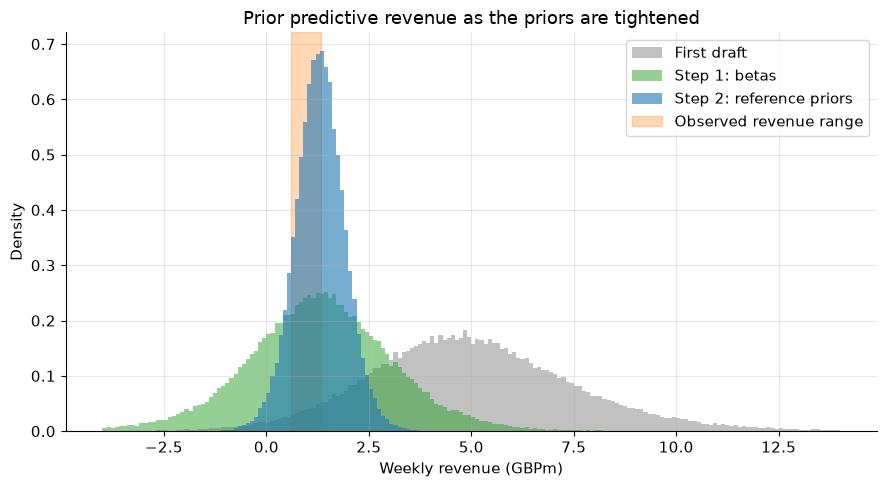

In [8]:
fig, ax = plt.subplots()
bins = np.linspace(-4, 14, 181)
ax.hist(pp_draft, bins=bins, color="0.6", alpha=0.6, density=True, label="First draft")
ax.hist(pp_step1, bins=bins, color="C2", alpha=0.5, density=True, label="Step 1: betas")
ax.hist(pp_step2, bins=bins, color="C0", alpha=0.6, density=True, label="Step 2: reference priors")
ax.axvspan(y.min(), y.max(), color="C1", alpha=0.3, zorder=0, label="Observed revenue range")
ax.set_xlabel("Weekly revenue (GBPm)")
ax.set_ylabel("Density")
ax.set_title("Prior predictive revenue as the priors are tightened")
ax.legend()
fig.tight_layout()

## Takeaway

The first draft's priors looked weakly informative in the model's internal units and implied a business several times Sedge's size, with an OOH return in the dozens.
Tightening the betas fixed the returns, and putting the remaining priors on revenue's own scale brought the simulated weeks into a plausible range, with only a small share below zero or above twice the largest week.
The final priors still leave the data plenty of room: they rule out businesses that could not exist, not the ones that might.
The general pattern is to sample from the priors alone, compare the implied outcomes with what domain knowledge says is plausible, and revise the least plausible priors first.
Every later lab that calls `reference_model` uses the priors chosen here.